# Data Science Project: Assessment 2

## Project title: Predictive Model of Cancer Recurrence and Clustering Analysis of Populations Among Thyroid Cancer Patients

## 


## Case study
I will be analyzing "Differentiated Thyroid Cancer Recurrence" data from the UC Irvine Machine Learning Repository. The data was collected over 15 years, with each patient followed for at least 10 years.

https://archive.ics.uci.edu/dataset/915/differentiated+thyroid+cancer+recurrence

## 1. Aims, objectives and plan 

### a) Aims and objectives
In this project, I aim to analyze patient data in order to determine patient factors that may influence the recurrence of Thyroid Cancer.

###  b) Plan
Week 1: Dataset selection, Background Research and Preliminary Data Exploration

Week 2: Pre-processing, Initial Predictive Model Development, Research into programming methods

Week 3: Predictive Model Finalization, K-Means Clustering Analysis, Results Evaluation and Discussion

## 2. Understanding the case study

###  Case study analysis
Borzooei, Briganti, Golparian, et al. collected the data used in this report for their study "Machine learning for risk stratification of thyroid cancer patients: a 15-year cohort study," published in October, 2023.

Their primary objective was to identify factors that contribute to Thyroid Cancer Recurrence. Thyroid Cancer has a relatively low mortality rate (around 1.7%, per the National Cancer Institute), but recurrence rates are relatively high (around 28% in this dataset, though that is with a limited sample group and is not necessarily the rates of the general population). Therefore, data with 16 demographic and clinical features was collected over 15 years to investigate how it may connect to recurrence.

Therefore, using a predictive model is a natural technique to apply. I have also chosen to apply K-Means Clustering, to investigate if any patterns emerge within patients that could allow for subsequent analysis of these subgroups.

## 3. Pre-processing applied 


In [220]:
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import silhouette_score
from sklearn.metrics import roc_curve
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


In [221]:
df = pd.read_csv('Thyroid_Diff.csv')

print(df.head())

   Age Gender Smoking Hx Smoking Hx Radiothreapy Thyroid Function  \
0   27      F      No         No              No        Euthyroid   
1   34      F      No        Yes              No        Euthyroid   
2   30      F      No         No              No        Euthyroid   
3   62      F      No         No              No        Euthyroid   
4   62      F      No         No              No        Euthyroid   

          Physical Examination Adenopathy       Pathology     Focality Risk  \
0   Single nodular goiter-left         No  Micropapillary    Uni-Focal  Low   
1          Multinodular goiter         No  Micropapillary    Uni-Focal  Low   
2  Single nodular goiter-right         No  Micropapillary    Uni-Focal  Low   
3  Single nodular goiter-right         No  Micropapillary    Uni-Focal  Low   
4          Multinodular goiter         No  Micropapillary  Multi-Focal  Low   

     T   N   M Stage       Response Recurred  
0  T1a  N0  M0     I  Indeterminate       No  
1  T1a  N0  M0  

###  Merging, pivoting and melting, if necessary

Data was retrieved in the form of a single table, so merging, pivoting, and melting were unneccessary.

### Categorical and numerical encoding

In [222]:
#First, we can check all the values in each column, so we can see which are binary and which are not
unique_values = {col: df[col].unique() for col in df.columns}
print(unique_values)

#Then, we can convert the categorical variables into numerical values

#Binary
#F = 1, M = 2
df['Gender'] = df['Gender'].replace({'F': 1, 'M': 0})
#Yes = 1, No = 0
df['Smoking'] = df['Smoking'].replace({'Yes': 1, 'No': 0})
df['Hx Smoking'] = df['Hx Smoking'].replace({'Yes': 1, 'No': 0})
df['Hx Radiothreapy'] = df['Hx Radiothreapy'].replace({'Yes': 1, 'No': 0})
df['Recurred'] = df['Recurred'].replace({'Yes': 1, 'No': 0})
#Multi-focal = 1, Uni-Focal = 0
df['Focality'] = df['Focality'].replace({'Multi-Focal': 1, 'Uni-Focal': 0})

#Ordinal
df['Risk'] = df['Risk'].replace({'Low': 0, 'Intermediate': 1, 'High': 2})
df['T'] = df['T'].replace({'T1a': 0, 'T1b': 1, 'T2': 2, 'T3a': 3, 'T3b': 4, 'T4a': 5, 'T4b': 6})
df['N'] = df['N'].replace({'N0': 0, 'N1a': 1, 'N1b': 2})
df['M'] = df['M'].replace({'M0': 0, 'M1': 1})
df['Stage'] = df['Stage'].replace({'I': 0, 'II': 1, 'III': 2, 'IVA': 3, 'IVB': 4})

#Nominal
#Instead of assigning a false order to Nominal variables by saying '0, 1, 2', we create a new binary column for each
df = pd.get_dummies(df, columns=['Thyroid Function', 'Physical Examination', 'Adenopathy', 'Pathology', 'Response'], dtype=int)
#df['Thyroid Function'] = df['Thyroid Function'].replace({'Euthyroid': 0, 'Clinical Hyperthyroidism': 1, 'Clinical Hypothyroidism': 2, 'Subclinical Hyperthyroidism': 3, 'Subclinical Hypothyroidism': 4})
#df['Physical Examination'] = df['Physical Examination'].replace({'Single nodular goiter-left': 0, 'Multinodular goiter': 1, 'Single nodular goiter-right': 2, 'Normal': 3, 'Diffuse goiter': 4})
#df['Adenopathy'] = df['Adenopathy'].replace({'No': 0, 'Right': 1, 'Extensive': 2, 'Left': 3, 'Bilateral': 4, 'Posterior': 5})
#df['Pathology'] = df['Pathology'].replace({'Micropapillary': 0, 'Papillary': 1, 'Follicular': 2, 'Hurthel cell': 3})
#df['Response'] = df['Response'].replace({'Indeterminate': 0, 'Excellent': 1, 'Structural Incomplete': 2, 'Biochemical Incomplete': 3})

print('\n'+'\n'+'\n')

#Finally, we can re-check all the unique values in each column, to check that they converted properly
unique_values = {col: df[col].unique() for col in df.columns}
print(unique_values)

{'Age': array([27, 34, 30, 62, 52, 41, 46, 51, 40, 75, 59, 49, 50, 76, 42, 44, 43,
       36, 70, 60, 33, 26, 37, 55, 31, 45, 20, 38, 29, 25, 21, 23, 24, 35,
       54, 22, 69, 28, 17, 73, 18, 39, 57, 66, 32, 47, 56, 63, 19, 67, 72,
       61, 68, 48, 81, 53, 58, 80, 79, 65, 15, 82, 71, 64, 78]), 'Gender': array(['F', 'M'], dtype=object), 'Smoking': array(['No', 'Yes'], dtype=object), 'Hx Smoking': array(['No', 'Yes'], dtype=object), 'Hx Radiothreapy': array(['No', 'Yes'], dtype=object), 'Thyroid Function': array(['Euthyroid', 'Clinical Hyperthyroidism', 'Clinical Hypothyroidism',
       'Subclinical Hyperthyroidism', 'Subclinical Hypothyroidism'],
      dtype=object), 'Physical Examination': array(['Single nodular goiter-left', 'Multinodular goiter',
       'Single nodular goiter-right', 'Normal', 'Diffuse goiter'],
      dtype=object), 'Adenopathy': array(['No', 'Right', 'Extensive', 'Left', 'Bilateral', 'Posterior'],
      dtype=object), 'Pathology': array(['Micropapillary', 'Papill

###  Preparing the labels appropriately


In [223]:
#the variable we're examining, the label, is "Recurred"
df['Recurred'].value_counts()

#We can seperate out the features
target_label = df['Recurred']
features = df.drop(columns=['Recurred'])

print(features.head())

   Age  Gender  Smoking  Hx Smoking  Hx Radiothreapy  Focality  Risk  T  N  M  \
0   27       1        0           0                0         0     0  0  0  0   
1   34       1        0           1                0         0     0  0  0  0   
2   30       1        0           0                0         0     0  0  0  0   
3   62       1        0           0                0         0     0  0  0  0   
4   62       1        0           0                0         1     0  0  0  0   

   ...  Adenopathy_Posterior  Adenopathy_Right  Pathology_Follicular  \
0  ...                     0                 0                     0   
1  ...                     0                 0                     0   
2  ...                     0                 0                     0   
3  ...                     0                 0                     0   
4  ...                     0                 0                     0   

   Pathology_Hurthel cell  Pathology_Micropapillary  Pathology_Papillary  \
0   

### Appropriate feature selection such as RFE

In [224]:
#Chi-Squared Test:
chi2_stats, p_values = chi2(features, target_label)

print(chi2_stats)
print('\n')

#We use functions of scikitlearn in order to select features for further investigation. We've converted to numerical values so
#we can use these functions.
selector = SelectKBest(score_func = chi2, k = 5)
new_features = selector.fit_transform(features, target_label)
scores = selector.scores_
p_values = selector.pvalues_

#We make a new dataframe showing each features Chi^2 and P Values (may just clutter report, decide on neccessity later)
features_scores = pd.DataFrame({'Features': features.columns, 'Chi^2 Scores': scores, 'P Values': p_values}).sort_values(by='Chi^2 Scores')
print(features_scores)

#We then see the k number of features most impactful
selected_features = features.columns[selector.get_support()].tolist()
print('Features Selected by Chi-Squared Test:')
print(selected_features)

#filter the original dataframe to only the selected features
chi_columns = selected_features
chi_df = features[chi_columns]



#RFE:

estimator = LogisticRegression(max_iter=100)
rfe_selector = RFE(estimator, n_features_to_select = 5, step = 1)
rfe_selector = rfe_selector.fit(features, target_label)
#make a new dataframe showing if each feature was selected by RFE, and their ranking
rfe_rankings = pd.DataFrame({'Features': features.columns, 'Selected?': rfe_selector.support_, 'Ranking': rfe_selector.ranking_})

#filter the original dataframe to only the selected features
rfe_columns = features.columns[rfe_selector.support_]
rfe_df = features[rfe_columns]

#We then see the k number of features most impactful
rfe_selected_features = features.columns[rfe_selector.get_support()].tolist()
print('Features Selected by RFE')
print(rfe_selected_features)



#Chi^2 selected the features Age, Risk, N, Stage, and Response_structural Incomplete.
#RFE selected Risk, Stage, Response_excellent, Response_indeterminate, and Response_structural Incomplete
#In further parts, we will examine the full features dataset, 'features,' as well as the feature-selected data in 
#'chi_df' and 'rfe_df'


[1.43510002e+02 7.64727661e+00 3.70909153e+01 6.57316498e+00
 1.14370563e+01 3.63792048e+01 1.96130221e+02 9.68497042e+01
 2.06909723e+02 4.58333333e+01 1.89759689e+02 1.72074242e+00
 7.88159371e-01 2.85554744e-01 1.96363636e+00 3.90594036e-01
 2.74909091e+00 5.53189418e+00 4.81000481e-04 4.52903568e-02
 4.64762290e+00 4.98771307e+01 1.78240741e+01 1.50873440e+01
 4.12691872e+01 5.09259259e+00 2.78939646e+01 2.97160173e+00
 3.20606061e-02 1.88509091e+01 1.41586316e+00 4.37628605e+00
 7.89255635e+01 8.42559419e+00 2.17744878e+02]


                                            Features  Chi^2 Scores  \
18                       Physical Examination_Normal      0.000481   
28                            Pathology_Hurthel cell      0.032061   
19   Physical Examination_Single nodular goiter-left      0.045290   
13                        Thyroid Function_Euthyroid      0.285555   
15       Thyroid Function_Subclinical Hypothyroidism      0.390594   
12          Thyroid Function_Clinical Hypot

###  Dealing with missing values (imputation, filtering) without leaking

With this line of code, we check if there are any missing values in the dataset. There are not, so we can proceed.

In [225]:
df.isna().values.any()

False

###  Dealing with duplicate values


In [226]:
df.duplicated().values.sum()
df[df.duplicated]

#there are 19 rows with duplicate values. These could be duplicates in the data or mistakes with collection, but are more 
#likely to be different patients with similar demographic data. For that reason, I've elected to still use duplicate data in
#my analysis.

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Focality,Risk,T,N,M,...,Adenopathy_Posterior,Adenopathy_Right,Pathology_Follicular,Pathology_Hurthel cell,Pathology_Micropapillary,Pathology_Papillary,Response_Biochemical Incomplete,Response_Excellent,Response_Indeterminate,Response_Structural Incomplete
32,36,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
38,40,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
40,51,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
66,35,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
69,51,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
77,29,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,1,0,0
120,37,1,0,0,0,0,0,2,0,0,...,0,0,0,0,0,1,0,1,0,0
121,26,1,0,0,0,0,0,2,0,0,...,0,0,0,0,0,1,0,1,0,0
123,28,1,0,0,0,0,0,2,0,0,...,0,0,0,0,0,1,0,1,0,0
132,32,1,0,0,0,0,0,2,0,0,...,0,0,0,0,0,1,0,1,0,0


### Variance analysis

In [227]:
#Only Age is a continuous variable
features["Age"].var()

#Variance seems to be suitable

229.0529028201168

### Appropriate feature extraction

Feature extraction is likely unnecessary, due to the established clinical value of the existing features, and the relatively small number of features. Principle Component Analysis was still performed for K-Means analysis, to verify if lower dimensionality would permit greater accuracy in clustering.

In [228]:
#Now, performing Principal Component Analysis (so as to more easily manage the data with K-Means)
#Change the data into Z-Scores, for proper comparison
scaler = StandardScaler()
feats_scaled = scaler.fit_transform(features)
#We use sci-kit learn to automatically determine the number of PCAs to explain at least 60% variance
#for exploratory purposes
pca = PCA(n_components = 0.6)
components = pca.fit_transform(feats_scaled)
pca_dataframe = pd.DataFrame(data = components)

how_many_components = pca.n_components_
print("PCA Number of Components: ")
print(how_many_components)

PCA Number of Components: 
10


### Identifying and dealing with class imbalance

In [229]:
target_label.value_counts()

#Class imbalance is about 72:28, in favor of "No." This is a mild imbalance, suggesting that when models are made, class weights
#may to be balanced, but no major adjustment to class imbalance needs to be done during pre-processing.

0    275
1    108
Name: Recurred, dtype: int64

### Identifying and dealing with outliers

In [230]:
#Age is the only continous variable
quantile1 = features["Age"].quantile(.25)
quantile3 = features["Age"].quantile(.75)

iqr = quantile3 - quantile1

upper_bound = quantile3 + 1.5 * iqr
lower_bound = quantile1 - 1.5 * iqr

outlier_df = features[(features["Age"] < lower_bound) | (features["Age"] > upper_bound)]
outlier_df

#There are no Ages outside the bounds (the highest Age is 82, nearly at the limit but not quite a likely outlier, 
#and the lowest is 15, well within the range)

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Focality,Risk,T,N,M,...,Adenopathy_Posterior,Adenopathy_Right,Pathology_Follicular,Pathology_Hurthel cell,Pathology_Micropapillary,Pathology_Papillary,Response_Biochemical Incomplete,Response_Excellent,Response_Indeterminate,Response_Structural Incomplete


### Dealing with correlation and collinearity, if necessary.

In [231]:
#correlation matrix -move down after converting categorical
correlation_matrix = df.corr()
print(correlation_matrix.head(10))

#There is some high collinearity - such as Risk and Adenopathy_No, and Risk and Recurred. This may inflate some 
#coefficient estimates. This is further reason to analyze rfe_df and chi_df, the feature-selected dataframes.

                      Age    Gender   Smoking  Hx Smoking  Hx Radiothreapy  \
Age              1.000000 -0.186457  0.309536    0.134531         0.176588   
Gender          -0.186457  1.000000 -0.621886   -0.175755        -0.235865   
Smoking          0.309536 -0.621886  1.000000    0.252773         0.297874   
Hx Smoking       0.134531 -0.175755  0.252773    1.000000         0.261198   
Hx Radiothreapy  0.176588 -0.235865  0.297874    0.261198         1.000000   
Focality         0.223847 -0.207634  0.238494    0.001204         0.102415   
Risk             0.295556 -0.295229  0.374324    0.138403         0.272056   
T                0.242670 -0.271949  0.377728    0.151056         0.225794   
N                0.061243 -0.238766  0.204305    0.044421         0.095535   
M                0.235401 -0.211540  0.321233    0.127209         0.430214   

                 Focality      Risk         T         N         M  ...  \
Age              0.223847  0.295556  0.242670  0.061243  0.235401  

## 4. Technique 1: Prediction

### Discuss your motivation for choosing the technique and provide a schematic figure of the process


The core finding that this dataset seeks to examine is the recurrence of Thyroid Cancer. As this is a binary value, we can use Logistic Regression to predict the probability of Thyroid Cancer recurrence given a patient's demographics. We will run a test/train split and tune the hyperparameters.

Workflow:

Raw Data -> Preprocessing (Feature Selection) -> Train/Test Split -> Regression Applied (Data Pipeline) -> Predictions -> Evaluation of Metrics

### Setting hyperparameters (Initial Model)


In [232]:
#Class Weight will be tuned later to address class imbalance

#For now I will use the following parameters (proper hyperparameters will be determined algorithmically in Part C):
#I will use C (the inverse of regularization strength), controlling overfitting
#I'll also use penalty, specifically L2, in order to deal with the potential colinnearity determined from pre-processing
#I will use the solver 'lbfgs', as it's a good default for a smaller-sized dataset like this

def run_logistic_model(x, y):
    #We run a train/test split for the full data set, and the feature-restricted data. We stratify to ensure class imbalance is dealt with
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.15, random_state=150, stratify = y)
    #convert to Z-scores for consistent comparison
    scale = StandardScaler()
    x_train_scaled = scale.fit_transform(x_train)
    x_test_scaled = scale.transform(x_test)
    #Make the logistic regression model
    logistic_model = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs')
    fitted_model = logistic_model.fit(x_train_scaled, y_train)
    #pull the results of the regression
    y_predictions = logistic_model.predict(x_test_scaled)
    y_probabilities = logistic_model.predict_proba(x_test_scaled)
    accuracy = accuracy_score(y_test, y_predictions)
    return [fitted_model, accuracy]


print("Full Dataset Accuracy:")
full_model = run_logistic_model(features, target_label)
print(full_model[1])
print("Chi-Squared Feature-Selected Accuracy:")
chi_model = run_logistic_model(chi_df, target_label)
print(chi_model[1])
print("RFE Feature-Selected Accuracy:")
rfe_model = run_logistic_model(rfe_df, target_label)
print(rfe_model[1])



Full Dataset Accuracy:
0.9655172413793104
Chi-Squared Feature-Selected Accuracy:
0.9310344827586207
RFE Feature-Selected Accuracy:
0.9655172413793104


### Optimising hyperparameters appropriately (Improved Model)


In [233]:
def run_logistic_model_find_hyper(x, y, _name):
    name = _name
    #We run a train/test split for the full data set, and the feature-restricted data. We stratify to ensure class imbalance is dealt with
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.15, random_state=150, stratify = y)
    
    #Make the logistic regression model, within a data Pipeline structure to ensure no data leakage from scaling the features manually afterwards
    data_pipe = Pipeline([
        ("Scaler", StandardScaler()),
        ("Logistic Model", LogisticRegression(max_iter = 1000, class_weight = 'balanced'))
    ]) 
    
    #Create a search grid for hyperparameters
    param_grid = [{
        
        "Logistic Model__C": np.logspace(-4,4,20),
        "Logistic Model__penalty": ['l2'],
        "Logistic Model__solver": ['lbfgs']
        
    },
    {
        "Logistic Model__C": np.logspace(-4,4,20),
        "Logistic Model__penalty": ['l1', 'l2'],
        "Logistic Model__solver": ['liblinear']
    },
    {
        "Logistic Model__C": np.logspace(-4,4,20),
        "Logistic Model__penalty": ['l1', 'l2'],
        "Logistic Model__solver": ['saga']
    }
        
    ]
    
    #Apply that search grid to get the best hyperparameters for the model - f1 is used for scoring, as identifying positive
    #cases of thyroid cancer recurrence is of utmost importance
    classifier = GridSearchCV(data_pipe,param_grid = param_grid, cv = 3, verbose=True,n_jobs=-1, scoring = "f1")
    
    #apply these hyperparameters to the model to create a better fitted model
    fitted_model = classifier.fit(x_train, y_train)
    best_est = fitted_model.best_estimator_
    
    #Print the highest score that the hyperparameters achieved, and which parameters have been found to be optimal for this model
    print("Cross-Validated Best Score:")
    print(classifier.best_score_)
    print("Cross-Validated Best Parameters:")
    print(classifier.best_params_)
    
    #Predict probability, for use in generating ROC-AUC score later
    pred_prob = best_est.predict_proba(x_test)[:,1]
    
    return {"Best Model": best_est, "Test X": x_test, "Test Y": y_test, "Pred Prob": pred_prob, "Name": name}


print("Full Dataset:")
full_model = run_logistic_model_find_hyper(features, target_label, "Full Model")

print("\nChi-Squared Feature-Selected:")
chi_model = run_logistic_model_find_hyper(chi_df, target_label, "Chi-Squared Feature Selected Model")

print("\nRFE Feature-Selected:")
rfe_model = run_logistic_model_find_hyper(rfe_df, target_label, "RFE Feature Selected Model")



Full Dataset:
Fitting 3 folds for each of 100 candidates, totalling 300 fits
Cross-Validated Best Score:
0.9251167970447631
Cross-Validated Best Parameters:
{'Logistic Model__C': 0.615848211066026, 'Logistic Model__penalty': 'l1', 'Logistic Model__solver': 'saga'}

Chi-Squared Feature-Selected:
Fitting 3 folds for each of 100 candidates, totalling 300 fits
Cross-Validated Best Score:
0.9196933010492332
Cross-Validated Best Parameters:
{'Logistic Model__C': 0.03359818286283781, 'Logistic Model__penalty': 'l1', 'Logistic Model__solver': 'liblinear'}

RFE Feature-Selected:
Fitting 3 folds for each of 100 candidates, totalling 300 fits
Cross-Validated Best Score:
0.9380102185102089
Cross-Validated Best Parameters:
{'Logistic Model__C': 0.012742749857031334, 'Logistic Model__penalty': 'l2', 'Logistic Model__solver': 'lbfgs'}


### Performance metrics for training set

Full Dataset Metrics:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        42
           1       1.00      0.88      0.93        16

    accuracy                           0.97        58
   macro avg       0.98      0.94      0.96        58
weighted avg       0.97      0.97      0.96        58


ROC AUC:
0.9389880952380953

Chi-Squared Feature-Selected Metrics:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        42
           1       1.00      0.75      0.86        16

    accuracy                           0.93        58
   macro avg       0.96      0.88      0.91        58
weighted avg       0.94      0.93      0.93        58


ROC AUC:
0.9851190476190476

RFE Feature-Selected Metrics:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        42
           1       1.00      0.88      0.93        16

    accuracy                    

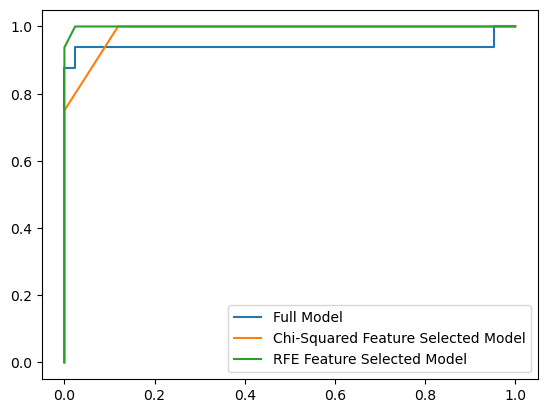

In [234]:
#Define a new function to test the trained data
def performance_metrics(trained_model):
    #test the model on the test data, using the hyperparemeters found by run_logistic_model_find_hyper()
    y_predictions = trained_model["Best Model"].predict(trained_model["Test X"])
    y_probabilities = trained_model["Best Model"].predict_proba(trained_model["Test X"])
    accuracy = accuracy_score(trained_model["Test Y"], y_predictions)
    report = classification_report(trained_model["Test Y"], y_predictions)
    print(report)
    #Determine the ROC AUC Score and Curve for model evaluation
    rocauc_score = roc_auc_score(trained_model["Test Y"], trained_model["Pred Prob"])
    fpr, tpr, thresholds = roc_curve(trained_model["Test Y"], trained_model["Pred Prob"])
    plt.plot(fpr,tpr, label = trained_model["Name"])
    plt.legend(loc = "lower right")
    print("\nROC AUC:")
    print(rocauc_score)
    return 


print("Full Dataset Metrics:")
performance_metrics(full_model)
print("\nChi-Squared Feature-Selected Metrics:")
performance_metrics(chi_model)
print("\nRFE Feature-Selected Metrics:")
performance_metrics(rfe_model)


## 5. Technique 2 : K-Means Clustering

### Discuss your motivation for choosing the technique and  provide a schematic figure of the process


For this second technique, I seek to find natural groupings in the data, potentially allowing us to determine clinically meaningful groupings for Thyroid Cancer Patients. 

We will use the Principal Components found with PCA to generate these clusters, as it reduces dimensionality and noise, and makes the distance metrics used by this analysis method more meaningful.

Workflow:

Raw Data -> Preprocessing (Principal Component Analysis + Scaling) -> Determine Optimal Number of Clusters (Elbow Method + Silhouette Score) -> K-Mean Cluster Generation -> Evaluation of Metrics

### Setting hyperparameters


First, we need to use the elbow method to find the optimal number of clusters for the model, and the silhouette method for similar purposes, and to determine how well the data naturally divides into clusters.

### Optimising hyperparameters appropriately


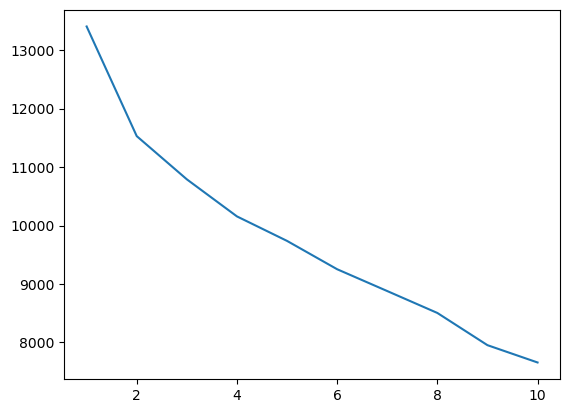

Silhouette Scores for (k=2 to k=10): 
[0.24089648389815344, 0.21191681827982917, 0.15126681408352236, 0.16112779088507714, 0.16040965220387263, 0.17451902571273287, 0.19363649897888496, 0.19445998739780465, 0.1913352089275123]


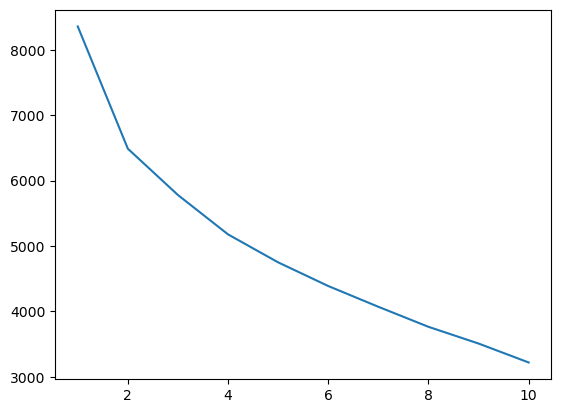

Silhouette Scores for (k=2 to k=10): 
[0.3147494777878728, 0.2788213824466414, 0.2411796921406009, 0.23745918940081773, 0.2638165650563222, 0.2562663003148138, 0.2780828469559209, 0.28503074775569853, 0.28800058327499156]


In [235]:
#a function to create the elbow-graph and determine sillhouette scores for a given dataframe of features
def determine_optimal_k(data_for_k_means):
    inertias = []
    sil_scores = []
    #Check the intertia for each number of clusters, 1 to 10
    k_values_to_check = range(1,11)
    for k in k_values_to_check:
        _kmean = KMeans(n_clusters = k, random_state=150).fit(data_for_k_means)
        inertias.append(_kmean.inertia_)
        #We can calculate the silhouette scores using a python module. It doesn't work at k=1, so we start after that
        _labels = _kmean.labels_
        if k > 1:
            sil_scores.append(silhouette_score(data_for_k_means, _labels))

    plt.plot(k_values_to_check, inertias)
    plt.show()
    print("Silhouette Scores for (k=2 to k=10): ")
    print(sil_scores)
    return
    
determine_optimal_k(feats_scaled)
determine_optimal_k(pca_dataframe)

#I believe that the elbow is best defined as k = 2. The silhouette score being the highest supports this conclusion.
#However, the score is only 0.24089648389815344. While I will continue and examine the K-means, this suggests that 
#the data likely lacks particularly meaningful groupings.

#In the second graph, we use the Principal Component Analysis to reduce dimensions, explaining 60% of variance. 
#This has relatively little impact on the data, so does not seem to be a worthy trade-off for the low variance explanation.
#The dimensionality-reduced data does not provide sufficiently improved insights to justify the loss of feature interpretability.
#This dataframe does give slightly higher silhouette scores. Further analysis could examine the data with low
#variance explanation, in order to create more meaningful clusters.

#Therefore, I will be using the non-PCA dataframe for following K-Means Clustering Analysis, due to it's aforementioned drawbacks.

### d) Performance metrics for training set

In [236]:
#Creating the k-means-driven groupings, using the "k" value determined before
def k_mean_function(data_for_k_means):
    
    _kmeans = KMeans(n_clusters=2, random_state=150).fit(data_for_k_means)
    
    #we re-make a dataframe using the scaled z-score data, so we can attach the cluster data and manipulate it
    z_score_df = pd.DataFrame(feats_scaled, columns = features.columns)
    
    print("Inertia:")
    print(_kmeans.inertia_)
    print("\nSize of clusters:")
    z_score_df['Cluster'] = _kmeans.labels_
    print(z_score_df['Cluster'].value_counts())
    print("\nMeans of clusters:")
    means = z_score_df.groupby('Cluster').mean()
    print("Cluster 1:")
    print(means.loc[0])
    print("Cluster 2:")
    print(means.loc[1])
    print("\nTop differences of means of clusters:")
    mean_differences = means.loc[1] - means.loc[0]
    print(mean_differences.abs().sort_values().head(5))

    return

k_mean_function(feats_scaled)


#Median is not a meaningful statistic in my regularized dataset, as it is primarily binary and will just give 0 or 1
#While still slight, a few features, such as possessing a pathological subtype of Hurthel cell carcinoma,
#seem to be relatively more indicative of useful patient clustering than other features

#There's somewhat of an imbalance between clusters, with over twice as many patients belonging to CLuster 0 as Cluster 1,
#but this does not seem to be a concerning disparity.

#Overall, Cluster 0 appears to define a younger, often female, group, generally at lower risk with less advanced complications
#(less cosymptomatic, less advanced cancer, better response to treatment) than Cluster 1. However, there is certainly overlap
#between the two groups, as despite 2 clusters seeming to be the best grouping of data, the clusters are not particularly 
#well-defined, so any results from these groupings should be taken with a grain of salt, and re-verified with further research.
#it is suitable to consider the entire population of patients as a singular cluster for further analysis.

Inertia:
11529.263745506221

Size of clusters:
0    277
1    106
Name: Cluster, dtype: int64

Means of clusters:
Cluster 1:
Age                                                -0.117779
Gender                                              0.179759
Smoking                                            -0.210094
Hx Smoking                                         -0.086686
Hx Radiothreapy                                    -0.109493
Focality                                           -0.274302
Risk                                               -0.483624
T                                                  -0.339087
N                                                  -0.520198
M                                                  -0.222070
Stage                                              -0.267679
Thyroid Function_Clinical Hyperthyroidism           0.024913
Thyroid Function_Clinical Hypothyroidism            0.027377
Thyroid Function_Euthyroid                         -0.011847
Thyroid Function_Subcl

## 6. Comparison of metrics performance for testing 

Regarding the Predictive Model:
In selecting the proper hyperparameters for Logistic Regression, we already used Cross-Validation in our GridSearch. The hyperparameters for the RFE-selected features had the highest score. Chi^2 Feature Selection has a lower recall, which means it identifies positive cases of Thyroid Cancer less well, so it is not as good for our purposes as the other methods. RFE seems to provide similar results to the full dataset, so could be used for increased processing speed. In addition, the ROC-AUC score, as clearly seen in the previously generated ROC graph, is over 0.999 for the model using RFE-selected features. This suggests that in addition to matching the full dataset in precision, recall, and F1 score, when we no longer look at a fixed decision threshold for our metrics, focusing on the current stage of Thyroid Cancer, risk evaluated by ATA guidelines, and response to treatment allows for by far the best predictive model.

The logistic model applied to each dataset has a 100% precision rate of determining positive outcomes. This is likely due to the involvement of "Response" as a feature with heavy importance, suggesting that clinical identification of initial treatment response can allow for an overly cautious approach to recurrance identification. This is a very useful result, as type 2 errors are exceptionally dangerous in this situation.

Regarding the Clustering Model:
The K-Means analysis showed low values for it's Silhouette Scores, only mildly mitigated when the dimensions were reduced by PCA. The trade-off for this mild improvement was a major lack of variance being explained by the PCA-modified-model, suggesting that the data's population does not have clearly evident subgroups. 

However, the value of subgroups can be compared. While not cross validation, examining the inertia with the Elbow method allowed us to visually see that there is at least a mild commonality when forming 2 clusters. 

## 7. Final recommendation of best model 

The primary objectives for this data were to 1) create a model for predicting recurrence of Thyroid Cancer based on patient data in order to better prepare patients and doctors for medically significant events and 2) identify trends within Thyroid Cancer patient populations in order to form classifications of types of patients, for more specialized support.

For the first objective, I was able to successfully create a model by using Recursive Feature Elimination to focus on the features of Stage, Risk, and Response in order to make predictions within the test cases with high results in accuracy, precision, and ROC-AUC score. In other words, my logistic model can act as a powerful diagnostic tool for predicting cancer recurrence with startling veracity. The model, even when not using the optimally selected features, had a very high positive prediction rate. This is very useful for clinicians, as while it is dangerous to falsely diagnose, it is far riskier to fail to diagnose cancer.

For the second objective, I examined possible k-means clusters in order to reduce the population into subgroups of patients. Unfortunately, the data indicated that there were not strong clusterings, signifying that patients do not appear to form subgroups based around the features analyzed, so any support provided for Thyroid Cancer patients ought to attempt to address the entire population instead of subgroups.

## 8. Conclusion 

The RFE predictive logistic model was deeply successful, while attempts to break the data into clusters based on K-means was not. The logistic model ought to have application in diagnosis and preventative care, due to it's particularly high metrics. 

My primary goal for further research would be to investigate possible instances of information leakage. Looking deeper into the diagnostic tools used to evaluate the features of risk and response could be deeply illuminating - it is possible that the professionals providing this diagnostic information used techniques of identification that do not allow for these metrics to be easily used as predictors. 

I would also hope to gain access to a wider array of patient data, so as to further investigate possible clustering patterns. While meaningful clusters were not generated by this dataset, features such as employment, pre-existing conditions, or lifestyle could potentially provide greater insight into Thyroid Cancer Patient sub-communities.

## 9. Bibliography (References)

Borzooei, S., Briganti, G., Golparian, M. et al. Machine learning for risk stratification of thyroid cancer patients: a 15-year cohort study. Eur Arch Otorhinolaryngol 281, 2095–2104 (2024). https://doi.org/10.1007/s00405-023-08299-w

"This dataset is licensed under a Creative Commons Attribution 4.0 International (CC BY 4.0) license.

This allows for the sharing and adaptation of the datasets for any purpose, provided that the appropriate credit is given."

https://seer.cancer.gov/statfacts/html/thyro.html

https://scikit-learn.org/stable/

https://medium.com/@mstffclkk/outlier-analysis-in-python-6c21a6183004
    
https://archive.ics.uci.edu/dataset/915/differentiated+thyroid+cancer+recurrence
    
https://www.geeksforgeeks.org/machine-learning/how-to-optimize-logistic-regression-performance/#hyperparameters-in-gridsearchcv

ChatGPT and Google Gemini:
Used in accordance with Assignment Amber category to:

-Act as a support tutor to aid in the research of a topic. 

-Test and debug any code you produce yourself as part of the assignment.

-Draft and structure your piece of work once you have worked through the problem.

-Provide ideas or inspiration to help you overcome a creative block.

-Give feedback on content or provide proof reading of content that you have generated yourself.

NOT to produce work for the assessment beyond what is outlined above
